# Práctica 2 — Regresión lineal múltiple: predecir el costo anual de un seguro médico

**Estudiante:** Ramiro Mamani Mamani


## Paso 01 — Preparar el entorno de trabajo

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

print("Librerías importadas correctamente")

Librerías importadas correctamente


| Librería / función | Uso |
|---|---|
| `pandas` (`pd`) | Cargar el archivo CSV en una tabla (DataFrame), explorarlo, separar columnas y convertir las variables de texto en columnas de 0 y 1 con `get_dummies`. |
| `matplotlib.pyplot` (`plt`) | Dibujar el gráfico de costo real vs. costo predicho para ver visualmente dónde acierta y dónde falla el modelo. |
| `train_test_split` | Dividir los datos en un conjunto de entrenamiento (para que el modelo aprenda) y uno de prueba (para evaluarlo con datos que no vio). |
| `LinearRegression` | Crear y entrenar el modelo de regresión lineal múltiple, que calcula el intercepto y un coeficiente por cada variable. |
| `r2_score` | Medir qué proporción de la variación del costo explica el modelo (R²). |
| `mean_absolute_error` | Medir en cuántos dólares se equivoca el modelo en promedio (MAE). |

## Paso 02 — Cargar y conocer los datos

In [2]:
df = pd.read_csv("insurance.csv")
df.shape

(1338, 7)

In [3]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


### Para entregar

- **¿Cuántos asegurados y columnas?** El dataset tiene **1 338 asegurados (filas)** y **7 columnas**, como muestra `df.shape = (1338, 7)`. Además, `df.info()` indica 1 338 valores no nulos en cada columna.
- **¿Qué representa una fila?** Cada fila es **un asegurado**: sus características personales (edad, sexo, IMC, hijos, si fuma y región) junto con el costo médico anual que le facturó el seguro.
- **¿Qué columnas son texto y cuáles números?**
  - Texto: `sex`, `smoker` y `region`. Son variables categóricas.
  - Números: `age` y `children` (enteros, `int64`), `bmi` y `charges` (decimales, `float64`).
- **¿Cuál es la variable a predecir?** `charges`, el costo médico anual en dólares. Las otras seis columnas son las variables de entrada.

## Paso 03 — Preparar los datos para el modelo

In [5]:
y = df["charges"]
X = df.drop(columns="charges")

X = pd.get_dummies(X, drop_first=True, dtype=int)

print(list(X.columns))
print("Número de columnas:", X.shape[1])

['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']
Número de columnas: 8


In [6]:
X.head()

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,0,1,0,0,1
1,18,33.770,1,1,0,0,1,0
2,28,33.000,3,1,0,0,1,0
3,33,22.705,0,1,0,1,0,0
4,32,28.880,0,1,0,1,0,0


### Para entregar

**Columnas de X:** `['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']`

- **¿En cuántas columnas se convirtieron las 6 variables?** En **8 columnas**. Las tres numéricas (`age`, `bmi`, `children`) quedan igual; `sex` (2 categorías) se convierte en 1 columna, `smoker` (2 categorías) en 1 columna y `region` (4 categorías) en 3 columnas: 3 + 1 + 1 + 3 = 8.
- **Categoría de referencia de cada variable** (la que no tiene columna propia):
  - `sex` → **female**
  - `smoker` → **no**
  - `region` → **northeast**

  `get_dummies` ordena las categorías alfabéticamente y elimina la primera.
- **¿Qué hace `drop_first=True` y por qué no se pierde información?** Elimina la columna de la primera categoría de cada variable. No se pierde información porque esa categoría queda identificada cuando todas las demás columnas valen 0. Por ejemplo, si `region_northwest = region_southeast = region_southwest = 0`, la persona necesariamente vive en *northeast*. Conservar todas las columnas sería redundante: en cada fila sumarían siempre 1, y esa columna podría calcularse exactamente a partir de las otras (y del intercepto). Esa dependencia perfecta, llamada *trampa de las variables ficticias* (multicolinealidad perfecta), hace que los coeficientes no queden determinados de forma única. Al quitar una categoría, cada coeficiente se interpreta como la diferencia respecto de la categoría de referencia.

## Paso 04 — Dividir en entrenamiento y prueba

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Entrenamiento:", X_train.shape[0], "filas")
print("Prueba:       ", X_test.shape[0], "filas")

Entrenamiento: 1070 filas
Prueba:        268 filas


### Para entregar

- **Tamaños:** **1 070 filas de entrenamiento** (80 %) y **268 filas de prueba** (20 %).
- **¿Por qué no evaluar con los mismos datos de entrenamiento?** Porque el modelo ajustó sus coeficientes precisamente para esos datos; medirlo ahí sería como tomar un examen con las mismas preguntas que se estudiaron. El resultado sería optimista y no diría nada sobre lo que le interesa a la compañía: qué tan bien estima el costo de **asegurados nuevos** que nunca vio. El conjunto de prueba simula esos clientes nuevos y permite detectar si el modelo memorizó (sobreajuste) en lugar de generalizar.
- **¿Qué hace `random_state`?** `train_test_split` mezcla las filas al azar antes de dividirlas. `random_state=42` fija la semilla del generador aleatorio, de modo que la división es **siempre la misma** cada vez que se ejecuta el notebook. Si no se fijara, cada ejecución elegiría otras filas para prueba y los coeficientes, el R², el MAE y las predicciones cambiarían ligeramente cada vez: los resultados no serían reproducibles, y el docente o cualquier otra persona no podría obtener exactamente los mismos números.

## Paso 05 — Entrenar el modelo

In [8]:
modelo = LinearRegression()
modelo.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[ 256.98, 337.09, 425.28,...,-370.68,-657.86,-809.8 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['age','bmi','children',...,'region_northwest','region_southeast', 'region_southwest']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.193e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)


### Para entregar

- **¿Qué calcula `fit`?** Usando solo los datos de entrenamiento, calcula el **intercepto** ($\beta_0$, guardado en `modelo.intercept_`) y los **8 coeficientes** ($\beta_1 \dots \beta_8$, guardados en `modelo.coef_`), uno por cada columna de `X`.
- **¿Qué criterio define los "mejores" coeficientes?** El método de **mínimos cuadrados ordinarios**: elige los valores que hacen mínima la suma de los errores al cuadrado entre el costo real y el predicho en el conjunto de entrenamiento:

$$\text{SSE} = \sum_{i=1}^{n} \left(y_i - \hat{y}_i\right)^2$$

  Al elevar al cuadrado, los errores positivos y negativos no se cancelan y los errores grandes se penalizan más que los pequeños.
- **Ecuación general del modelo con las variables de X:**

$$\widehat{charges} = \beta_0 + \beta_1\,age + \beta_2\,bmi + \beta_3\,children + \beta_4\,sex\_male + \beta_5\,smoker\_yes + \beta_6\,region\_northwest + \beta_7\,region\_southeast + \beta_8\,region\_southwest$$

  Con los valores obtenidos (Paso 07), el modelo ajustado queda aproximadamente:

$$\widehat{charges} = -11\,931 + 257\,age + 337\,bmi + 425\,children - 19\,sex\_male + 23\,651\,smoker\_yes - 371\,region\_nw - 658\,region\_se - 810\,region\_sw$$

## Paso 06 — Evaluar el modelo

In [9]:
y_pred = modelo.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mediana = df["charges"].median()

print(f"R²  : {r2:.4f}")
print(f"MAE : {mae:,.2f} USD")
print(f"Mediana de charges: {mediana:,.2f} USD")
print(f"MAE / mediana     : {mae / mediana:.1%}")

R²  : 0.7836
MAE : 4,181.19 USD
Mediana de charges: 9,382.03 USD
MAE / mediana     : 44.6%


### Para entregar

**Resultados:** R² ≈ **0.784** y MAE ≈ **4 181 USD**. Mediana del costo ≈ **9 382 USD**.

- **Significado del R²:** el modelo explica alrededor del **78 %** de la variación del costo médico anual entre los asegurados de prueba. El 22 % restante corresponde a factores que el modelo no capta (otras características de la persona o relaciones que no son lineales).
- **Significado del MAE:** en promedio, la estimación del costo anual de un asegurado nuevo se equivoca en unos **4 181 dólares**, ya sea por arriba o por abajo.
- **Comparación con la mediana:** un seguro típico cuesta unos 9 382 USD, así que el error promedio equivale aproximadamente al **45 % del costo típico**. Para una compañía que fija primas individuales es un error **grande**: en un cliente típico, el precio podría quedar casi a mitad de camino del costo real. En el Paso 08 se ve además que los errores no son iguales para todos: para los asegurados más caros el modelo se queda corto por varios miles de dólares.
- **¿Es aceptable?** Como **primer modelo** y como herramienta para **entender** qué encarece el seguro, sí: explica casi 4/5 de la variación, sus coeficientes tienen sentido y se interpretan en dólares. Pero **no es suficiente para fijar primas individuales** sin mejoras: subestima sistemáticamente a los clientes de alto costo, que es justo el error que más dinero le hace perder a la compañía. Se podría mejorar añadiendo una interacción entre fumar e IMC, o un término de edad al cuadrado, manteniendo la interpretabilidad.

## Paso 07 — Interpretar los coeficientes

In [10]:
print(f"Intercepto: {modelo.intercept_:,.2f} USD")

Intercepto: -11,931.22 USD


In [11]:
coeficientes = pd.Series(modelo.coef_, index=X.columns).sort_values()
coeficientes.round(2)

region_southwest     -809.80
region_southeast     -657.86
region_northwest     -370.68
sex_male              -18.59
age                   256.98
bmi                   337.09
children              425.28
smoker_yes          23651.13
dtype: float64

In [12]:
# Apoyo para la última pregunta: efecto máximo de cada variable en su rango de valores
rango = X.max() - X.min()
efecto_en_rango = (coeficientes * rango[coeficientes.index]).round(0)
pd.DataFrame({"coeficiente": coeficientes.round(2),
              "rango de la variable": rango[coeficientes.index],
              "efecto en todo el rango (USD)": efecto_en_rango})

,coeficiente,rango de la variable,efecto en todo el rango (USD)
region_southwest,-809.80,1.00,-810.0
region_southeast,-657.86,1.00,-658.0
region_northwest,-370.68,1.00,-371.0
sex_male,-18.59,1.00,-19.0
age,256.98,46.00,11821.0
bmi,337.09,37.17,12530.0
children,425.28,5.00,2126.0
smoker_yes,23651.13,1.00,23651.0


### Para entregar

**Tabla de coeficientes (USD):** `region_southwest` −810 · `region_southeast` −658 · `region_northwest` −371 · `sex_male` −19 · `age` 257 · `bmi` 337 · `children` 425 · `smoker_yes` 23 651. Intercepto: −11 931.

- **¿Qué variable aumenta más el costo?** **`smoker_yes`**, con diferencia: fumar aumenta el costo anual estimado en unos **23 651 USD**, más que el costo de un seguro típico completo.
- **Interpretación de una variable numérica (`age`):** manteniendo fijas las demás características, **cada año adicional de edad aumenta el costo anual esperado en unos 257 USD**. Una persona de 50 años costaría unos 2 570 USD más al año que una de 40 con el mismo perfil.
- **Interpretación de una variable binaria (`smoker_yes`):** comparado con la categoría de referencia **no fumador**, una persona que **fuma** tiene un costo anual esperado unos **23 651 USD mayor**, con la misma edad, IMC, hijos, sexo y región. Otro ejemplo: `region_southwest = −810` indica que vivir en el *southwest* se asocia con un costo unos 810 USD menor que vivir en *northeast* (la referencia). `sex_male = −19` indica que ser hombre prácticamente no cambia el costo respecto de ser mujer (referencia).
- **¿Tiene sentido práctico el intercepto?** **No.** −11 931 USD sería el costo de una persona con 0 años de edad, IMC 0, sin hijos, mujer, no fumadora y del *northeast*. Esa persona no existe (en los datos la edad mínima es 18 y el IMC mínimo ≈ 16), y un costo negativo es imposible. El intercepto solo sirve para ubicar correctamente el plano de regresión dentro del rango de datos reales.
- **¿Por qué un coeficiente pequeño no implica poca influencia?** Porque el coeficiente mide el efecto de **una unidad** de la variable, y cada variable tiene una escala distinta. `age` tiene un coeficiente de "solo" 257 USD, pero va de 18 a 64 años: entre el asegurado más joven y el mayor hay una diferencia de unos 46 × 257 ≈ **11 800 USD**. `bmi` (337 USD por punto) varía de unos 16 a 53, un efecto de ≈ **12 500 USD**. En cambio, una variable binaria solo cambia de 0 a 1, así que su efecto total es su propio coeficiente. Para comparar la influencia real hay que multiplicar el coeficiente por el rango (o la desviación estándar) de la variable, como en la tabla de arriba, o estandarizar las variables antes de entrenar.

## Paso 08 — Visualizar las predicciones

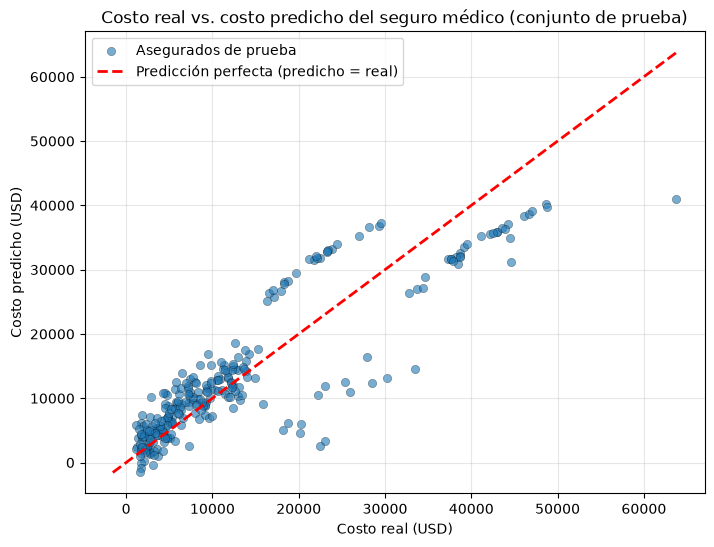

In [13]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.6, edgecolor="k", linewidth=0.3, label="Asegurados de prueba")

limites = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(limites, limites, "r--", linewidth=2, label="Predicción perfecta (predicho = real)")

plt.title("Costo real vs. costo predicho del seguro médico (conjunto de prueba)")
plt.xlabel("Costo real (USD)")
plt.ylabel("Costo predicho (USD)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [14]:
# Apoyo numérico para la lectura del gráfico: error promedio por rango de costo real
error = y_pred - y_test          # positivo = sobrestima, negativo = subestima
rangos = pd.cut(y_test, bins=[0, 10_000, 30_000, 70_000],
                labels=["< 10 000", "10 000 - 30 000", "> 30 000"])
pd.DataFrame({"n": error.groupby(rangos, observed=True).size(),
              "MAE (USD)": error.abs().groupby(rangos, observed=True).mean().round(0),
              "error medio (USD)": error.groupby(rangos, observed=True).mean().round(0)})

,n,MAE (USD),error medio (USD)
charges,,,
< 10 000,155,2346.0,1664.0
10 000 - 30 000,80,6044.0,928.0
> 30 000,33,8285.0,-8285.0


In [15]:
# Comprobación de la hipótesis: costo medio según fumar y obesidad (IMC >= 30)
df.assign(obesidad=df["bmi"] >= 30).groupby(["smoker", "obesidad"])["charges"] \
  .agg(["count", "mean"]).round(0)

count     mean
smoker obesidad                
no     False       502   7977.0
       True        562   8843.0
yes    False       129  21363.0
       True        145  41558.0

### Para entregar

- **¿Dónde predice mejor y dónde peor?** El modelo predice **mejor en los costos bajos** (menos de unos 10 000–12 000 USD). Ahí está la mayoría de los asegurados, los puntos forman una nube pegada a la diagonal y el error medio absoluto es de unos 2 300 USD. Predice **peor en los costos medios y altos** (más de unos 15 000 USD): entre 10 000 y 30 000 USD el error medio es de unos 6 000 USD, y por encima de 30 000 USD supera los 8 000 USD. Un detalle llamativo: para algunos asegurados muy baratos el modelo incluso predice costos **negativos**, que son imposibles.
- **¿Puntos por encima o por debajo de la diagonal?** Hay alejamientos en ambos sentidos, según la zona:
  - Con costos reales **mayores de 30 000 USD**, todos los puntos quedan **por debajo** de la diagonal: el modelo **subestima** a los clientes más caros (en promedio, unos 8 300 USD menos de lo real). El caso extremo cuesta unos 64 000 USD y el modelo le predice unos 41 000.
  - Con costos reales de **15 000–30 000 USD**, hay un grupo **por encima** de la diagonal (predicciones de 25 000–37 000 USD): ahí el modelo **sobrestima**.
  - También hay puntos dispersos muy **por debajo**, con costos reales de 18 000–35 000 USD y predicciones de solo 3 000–16 000 USD: personas que el modelo considera de bajo riesgo pero tuvieron gastos altos.

  Para la compañía, la subestimación es el error más peligroso, porque cobraría menos de lo que luego tendrá que pagar.
- **¿Grupos separados?** Sí. Las predicciones se separan en **dos franjas** claramente distintas: una nube grande de predicciones bajas (unos 0–18 000 USD) y una franja de predicciones altas (unos 25 000–41 000 USD), con un "hueco" entre ambas. La franja alta, a su vez, se divide en dos grupos: uno por encima de la diagonal (costos reales de unos 16 000–30 000 USD) y otro por debajo (costos reales de unos 33 000–50 000 USD).
- **Hipótesis:** la franja alta corresponde a los **fumadores**, porque `smoker_yes` suma unos 23 651 USD a la predicción y "salta" a esas personas por encima del hueco. Dentro de ella, los mayores errores los provocan los **fumadores con obesidad (IMC ≥ 30)**, que el modelo subestima, mientras que sobrestima a los fumadores con IMC normal. La tabla de apoyo lo respalda: los no fumadores cuestan en promedio unos 8 000–8 800 USD con o sin obesidad, los fumadores sin obesidad unos 21 400 USD y los fumadores con obesidad unos **41 600 USD**. Es decir, el efecto de fumar depende del IMC (es una **interacción**). El modelo lineal asume que fumar suma siempre lo mismo y que cada punto de IMC suma siempre 337 USD, para cualquier persona. En el conjunto de prueba, el MAE de los fumadores es de unos 8 300 USD, frente a unos 3 100 USD de los no fumadores. Los puntos dispersos muy por debajo de la diagonal serían, en cambio, no fumadores con gastos médicos inesperados (accidentes, enfermedades) que ninguna de las 6 variables de la solicitud puede anticipar. Añadir una variable `smoker_yes × bmi` (o `smoker_yes × obesidad`) probablemente reduciría mucho el error del primer tipo.

## Paso 09 — Predecir el costo de nuevos solicitantes

In [16]:
nuevos = pd.DataFrame({
    "age":      [45, 45, 25],
    "sex":      ["male", "male", "female"],
    "bmi":      [33.5, 33.5, 22.0],
    "children": [2, 2, 0],
    "smoker":   ["yes", "no", "no"],
    "region":   ["southeast", "southeast", "northwest"],
}, index=["A", "B", "C"])
nuevos

,age,sex,bmi,children,smoker,region
A,45,male,33.5,2,yes,southeast
B,45,male,33.5,2,no,southeast
C,25,female,22.0,0,no,northwest


In [17]:
# Tal como indica la guía: get_dummies con drop_first=True + reindex
nuevos_dummies = pd.get_dummies(nuevos, drop_first=True, dtype=int)
print("Columnas generadas para los nuevos:", list(nuevos_dummies.columns))

nuevos_X = nuevos_dummies.reindex(columns=X.columns, fill_value=0)
nuevos_X

Columnas generadas para los nuevos: ['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_southeast']


,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
A,45,33.5,2,1,1,0,1,0
B,45,33.5,2,1,0,0,1,0
C,25,22.0,0,0,0,0,0,0


⚠️ **Observación importante.** Con solo tres solicitantes, `get_dummies(..., drop_first=True)` elimina la primera categoría **presente en estos datos**, no la de entrenamiento. En `region` solo aparecen *northwest* y *southeast*, así que se elimina **`region_northwest`**. Después de `reindex`, la solicitante C queda con todas las regiones en 0, como si viviera en *northeast*, cuando en realidad vive en *northwest*.

Para evitarlo, en los datos nuevos se codifica **sin** `drop_first` y `reindex` se encarga de quedarse exactamente con las columnas de entrenamiento (descarta `sex_female`, `smoker_no`, etc. y rellena con 0 las que falten):

In [18]:
# Forma correcta: get_dummies SIN drop_first y luego reindex con las columnas de X
nuevos_X = pd.get_dummies(nuevos, dtype=int).reindex(columns=X.columns, fill_value=0)
nuevos_X

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
A,45,33.5,2,1,1,0,1,0
B,45,33.5,2,1,0,0,1,0
C,25,22.0,0,0,0,1,0,0


In [19]:
nuevos["costo_predicho_USD"] = modelo.predict(nuevos_X).round(2)
nuevos

,age,sex,bmi,children,smoker,region,costo_predicho_USD
A,45,male,33.5,2,yes,southeast,34750.52
B,45,male,33.5,2,no,southeast,11099.39
C,25,female,22.0,0,no,northwest,1538.53


In [20]:
diferencia = nuevos.loc["A", "costo_predicho_USD"] - nuevos.loc["B", "costo_predicho_USD"]
print(f"Diferencia A - B: {diferencia:,.2f} USD")
print(f"Coeficiente smoker_yes: {coeficientes['smoker_yes']:,.2f} USD")

Diferencia A - B: 23,651.13 USD
Coeficiente smoker_yes: 23,651.13 USD


### Para entregar

**Predicciones del costo anual:**

| Solicitante | Perfil | Costo predicho |
|---|---|---|
| A | 45 años, hombre, IMC 33.5, 2 hijos, **fumador**, southeast | ≈ **34 751 USD** |
| B | 45 años, hombre, IMC 33.5, 2 hijos, **no fumador**, southeast | ≈ **11 099 USD** |
| C | 25 años, mujer, IMC 22.0, sin hijos, no fumadora, northwest | ≈ **1 539 USD** |

(Con el procedimiento literal de la guía, C sale ≈ 1 909 USD porque se le trata como si fuera de *northeast*. La diferencia, unos 371 USD, es exactamente el coeficiente de `region_northwest`.)

- **¿Por qué es necesario `reindex`?** El modelo fue entrenado con **8 columnas en un orden fijo** y cada coeficiente está asociado a una posición. `get_dummies` sobre los datos nuevos solo crea columnas para las categorías que aparecen en ellos: aquí no hay nadie de *southwest*, por ejemplo, así que esa columna no existiría. `reindex(columns=X.columns, fill_value=0)` garantiza que los nuevos datos tengan **exactamente las mismas columnas, con los mismos nombres y en el mismo orden** que `X`, rellenando con 0 las que falten y descartando las que sobren.
- **¿Qué pasaría sin él?** `modelo.predict` daría un **error**, porque la cantidad o los nombres de las columnas no coinciden con los del entrenamiento (scikit-learn verifica los nombres de las variables). Y si por casualidad coincidiera la cantidad pero no el orden, sería peor: el modelo multiplicaría cada valor por el coeficiente equivocado y daría **predicciones incorrectas sin avisar**.
- **Diferencia entre A y B:** A y B solo se diferencian en que A fuma. La predicción de A supera a la de B en **≈ 23 651 USD**, que coincide exactamente con el **coeficiente de `smoker_yes`** del Paso 07. Como todas las demás variables son iguales, sus términos se cancelan en la resta y solo queda el efecto de fumar. Esta es precisamente la interpretación "manteniendo las demás variables fijas" de un coeficiente.

## Conclusión

El modelo de regresión lineal múltiple explica cerca del 78 % de la variación del costo médico anual (R² ≈ 0.78), con un error promedio de unos 4 200 USD. El factor que más encarece el seguro es fumar (≈ +23 650 USD al año), seguido por la edad y el IMC, que tienen coeficientes "pequeños" pero un efecto grande a lo largo de su rango. Sexo y región influyen muy poco. La principal debilidad del modelo es que subestima a los asegurados más caros, sobre todo a los fumadores con obesidad, porque supone que los efectos se suman de forma independiente. Incorporar la interacción fumador × IMC es la mejora más clara.